In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import subprocess

## Stereo

In [2]:
path = r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn-imperfections\audio\69_codec.mp3"
wave, sr = sf.read(path)
wave = wave.mT
wave.shape

(2, 246843)

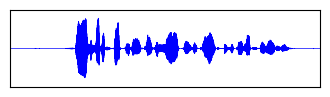

In [3]:
plt.style.use('default')

fig, axs = plt.subplots(1, 1, figsize=(4, 1))

# xlim = (0, wave.shape[1] / sr)
xlim = (0, 5)
ylim = (-0.6, 0.6)
colors = ["blue", "red", "cyan", "orange"]
times = np.arange(wave.shape[1]) / sr

plt.sca(axs)
plt.plot(times, wave[0], color=colors[0], linewidth=0.5)
plt.xlim(xlim)
plt.ylim(ylim)
plt.xticks([])
plt.yticks([])

plt.savefig("fig.png", dpi=300)
plt.show()

## Diagrams for Webpage

In [ ]:
# Sine wave.
duration = 5
samplerate = 16000
times = np.arange(0, duration, 1/samplerate)
freq = 100
waveform = np.sin(2 * np.pi * freq * times)
# waveform[:160] = 0
waveform = np.stack([waveform, waveform])
waveform_g722 = np.copy(waveform)
print(waveform_g722.shape)

In [ ]:
def g722_roundtrip(in_wav, out_wav, tmp_g722="tmp.g722"):
    subprocess.run([
        "ffmpeg", "-y",
        "-i", str(in_wav),
        "-ar", "16000", "-ac", "1",
        "-c:a", "g722",
        str(tmp_g722)
    ], check=True)

    subprocess.run([
        "ffmpeg", "-y",
        "-f", "g722",
        "-i", str(tmp_g722),
        "-ar", "16000",
        "-ac", "1",
        str(out_wav)
    ], check=True)

In [ ]:
sf.write(file="wave.wav", data=waveform_g722[1], samplerate=samplerate)
g722_roundtrip("wave.wav", "wave_g722.wav")
os.remove("wave.wav")
os.remove("tmp.g722")

In [ ]:
tmp_722, _ = sf.read("wave_g722.wav")
print(tmp_722.shape)

In [ ]:
waveform_g722[1] = tmp_722

In [ ]:
waveform_g722.shape

In [ ]:
t_min = 0
t_max = int(samplerate * 0.1)

fig, axs = plt.subplots(figsize=(10, 2.5))

plt.sca(axs)

plt.plot(times[t_min:t_max], waveform_g722[0, t_min:t_max], label="Channel 1 (ref.)")
plt.plot(times[t_min:t_max], waveform_g722[1, t_min:t_max], label="Channel 2")

plt.grid()
plt.legend()

plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Codec G.722 Imperfections (Sine Freq. = 100 Hz | SR = 16 kHz)")

fig.tight_layout()
plt.savefig(r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn-imperfections\images\g722.png", dpi=300)
plt.show()

### STO

In [ ]:
# Sine wave.
duration = 0.1
samplerate = 16000
times = np.arange(0, duration, 1/samplerate)
freq = 100
waveform = np.sin(2 * np.pi * freq * times)
waveform = np.stack([waveform, waveform])
waveform_g722 = np.copy(waveform)
print(waveform_g722.shape)

In [ ]:
def add_sto(waveform: np.ndarray, sto_samples: int = 0, channels: list[int] = [1, 3]):
    waveform_sto = np.copy(waveform)
    for c in channels:
        waveform_sto[c] = np.pad(waveform_sto[c, :-sto_samples], (sto_samples, 0))
    return waveform_sto

In [ ]:
200/16000

In [ ]:
waveform_sto = add_sto(waveform, 200, channels=[1])

fig, axs = plt.subplots(figsize=(10, 2.5))

plt.sca(axs)

plt.plot(times, waveform_sto[0], label="Channel 1 (ref.)")
plt.plot(times, waveform_sto[1], label="Channel 2")

plt.grid()
plt.legend()

plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Sampling-Time Offset (Sine Freq. = 100 Hz | SR = 16 kHz | STO = 12.5 ms)")

fig.tight_layout()
plt.savefig(r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn-imperfections\images\sto.png", dpi=300)
plt.show()

In [ ]:
def add_sro(waveform: np.ndarray, sro_ppm: float = 0, channels: list[int] = [1, 3]):
    sro_alpha = 1 / (1 + sro_ppm*1e-6)
    samples = np.arange(waveform.shape[1])
    samples_sro = sro_alpha * samples    
    waveform_sro = np.copy(waveform)
    for c in channels:
        waveform_sro[c] = np.interp(x=samples_sro, xp=samples, fp=waveform_sro[c])
    return waveform_sro

In [ ]:
waveform_sro = add_sro(waveform, 10000, channels=[1])

fig, axs = plt.subplots(figsize=(10, 2.5))

plt.sca(axs)

plt.plot(times[:t_max], waveform_sro[0, :t_max], label="Channel 1 (ref.)")
plt.plot(times[:t_max], waveform_sro[1, :t_max], label="Channel 2")

plt.grid()
plt.legend()
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Sampling-Rate Offset (Sine Freq. = 100 Hz | SR = 16 kHz | SRO = 10000 ppm)")

fig.tight_layout()
# plt.savefig(r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn_imperfections\images\sro.png", dpi=300)
plt.show()

### PL

In [ ]:
def add_packet_loss_gilbert(waveform: np.ndarray, packet_len: int = 256, packet_loss_rate: float = 0.05, mean_burst_len: int = 512, channels: list[int] = [1, 3]):
    waveform_pl = np.copy(waveform)

    p_bg = packet_len / mean_burst_len
    p_gb = p_bg * packet_loss_rate / (1.0 - packet_loss_rate)
    
    n_state_bad = False
    for n in range(0, waveform.shape[1], packet_len):
        if n_state_bad:
            for c in channels:
                waveform_pl[c, n:n+packet_len] = np.zeros(packet_len) if n+packet_len < waveform.shape[1] else np.zeros(waveform.shape[1]-n)    
            if np.random.rand() < p_bg:
                n_state_bad = False
        else:
            if np.random.rand() < p_gb:
                n_state_bad = True

    return waveform_pl

In [ ]:
waveform_pl = add_packet_loss_gilbert(waveform, packet_len=50, packet_loss_rate=0.15, mean_burst_len=100, channels=[1])

In [ ]:

fig, axs = plt.subplots(figsize=(10, 2.5))

plt.sca(axs)

plt.plot(times, waveform_pl[0], label="Channel 1 (ref.)")
plt.plot(times, waveform_pl[1], label="Channel 2",)

plt.grid()
plt.legend()
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Packet Loss (Sine Freq. = 100 Hz | SR = 16 kHz | PL Rate = 15% | Mean Burst Len. = 100 Samples)")

fig.tight_layout()
# plt.savefig(r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn_imperfections\images\pl.png", dpi=300)
plt.show()

In [ ]:
# file_path_src = r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn-imperfections\audio\69.wav"
# x, sr = sf.read(file_path_src)
# x = x.mT
file_path_dst = r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn-imperfections\audio\69_stereo.mp3"
x, sr = sf.read(file_path_dst)
x = x.mT
# sf.write(file_path_dst, x[:2].mT, sr)

In [ ]:
c = [1,]
x_sto = add_sto(x, sto_samples=40, channels=c)
x_sro = add_sro(x, sro_ppm=60, channels=c)
x_pl = add_packet_loss_gilbert(x, packet_len=256, packet_loss_rate=0.1, mean_burst_len=512, channels=c)

file_path_sto = r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn_imperfections\audio\69_sto.mp3"
file_path_sro = r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn_imperfections\audio\69_sro.mp3"
file_path_pl = r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn_imperfections\audio\69_pl.mp3"

# sf.write(file_path_sto, x_sto[:2].mT, sr)
# sf.write(file_path_sro, x_sro[:2].mT, sr)
# sf.write(file_path_pl, x_pl[:2].mT, sr)

## Diagrams for GN Report

In [2]:
n_path = r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn-imperfections\audio\00000\noisy_mixture.flac"
x_path = r"C:\Users\toviste\Local_Documents\code\ovistetom.github.io\wasn-imperfections\audio\00000\target_speech.flac"

In [3]:
n_wave, sr = sf.read(n_path)
n_wave = n_wave.T
x_wave, _ = sf.read(x_path)
x_wave = x_wave.T[0]

LibsndfileError: Error opening 'C:\\Users\\toviste\\Local_Documents\\code\\ovistetom.github.io\\wasn-imperfections\\audio\\00000\\noisy_mixture.flac': System error.

In [ ]:
# plt.style.use('dark_background')
plt.style.use('default')

fig, axs = plt.subplots(4, 1, figsize=(8, 4))

xlim = (0, n_wave.shape[1] / sr)
ylim = (-0.6, 0.6)
colors = ["blue", "red", "cyan", "orange"]
times = np.arange(n_wave.shape[1]) / sr

for i in range(4):
    plt.sca(axs[i])
    plt.plot(times, n_wave[i], color=colors[i], linewidth=0.5)
    plt.grid()
    plt.xlim(xlim)
    plt.ylabel(f"Chan. {i}")
    plt.ylim(ylim)
    if i == 0:
        axs[i].set_xticklabels([])
        plt.title("Noisy Mixture (Synchronized Channels)")
    elif i != 3:
        axs[i].set_xticklabels([])
    else:
        plt.xlabel("Time [s]")

fig.tight_layout()
plt.show()

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(8, 1.5))

xlim = (0, n_wave.shape[1] / sr)
ylim = (-0.6, 0.6)
colors = ["blue", "cyan", "red", "orange"]
times = np.arange(n_wave.shape[1]) / sr

plt.sca(axs)
plt.plot(times, x_wave, color=colors[0], linewidth=0.5)
plt.grid()
plt.xlim(xlim)
plt.ylabel("Chan. 0")
plt.ylim(ylim)
plt.xlabel("Time [s]")
plt.title("Target Speech")

fig.tight_layout()
plt.show()

In [ ]:
# plt.style.use('dark_background')
plt.style.use('default')

fig, axs = plt.subplots(2, 1, figsize=(8, 2))

xlim = (0, n_wave.shape[1] / sr)
ylim = (-0.6, 0.6)
colors = ["blue", "cyan", "red", "orange"]
times = np.arange(n_wave.shape[1]) / sr

for c in range(2):
    plt.sca(axs[c])
    plt.plot(times, n_wave[c], color=colors[c], linewidth=0.5)
    plt.grid()
    plt.xlim(xlim)
    plt.ylabel(f"Chan. {2*c}")
    plt.ylim(ylim)
    if c != 1:
        plt.title("Noisy Mixture (Synchronized Channels)")
        axs[c].set_xticklabels([])
plt.xlabel("Time [s]")

fig.tight_layout()
plt.show()

In [ ]:
packet_len = 512
n_pl = add_packet_loss_gilbert(n_wave, packet_len=packet_len, packet_loss_rate=0.15, mean_burst_len=3072)

In [ ]:
fig, axs = plt.subplots(4, 1, figsize=(8, 4))

xlim = (0, n_wave.shape[1] / sr)
ylim = (-0.6, 0.6)
colors = ["blue", "red", "cyan", "orange"]
times = np.arange(n_wave.shape[1]) / sr

for c in range(4):
    plt.sca(axs[c])     

    plt.plot(times, n_pl[c], color=colors[c], linewidth=0.5)

    plt.grid()
    plt.xlim(xlim)
    plt.ylabel(f"Chan. {c}")
    plt.ylim(ylim)
    if c == 0:
        axs[c].set_xticklabels([])
        plt.title("Noisy Mixture (Imperfect Channels)")
    elif c != 3:
        axs[c].set_xticklabels([])
    else:
        plt.xlabel("Time [s]")

fig.tight_layout()
plt.show()

In [ ]:
fig, axs = plt.subplots(4, 1, figsize=(8, 4))

xlim = (0, n_wave.shape[1] / sr)
ylim = (-0.6, 0.6)
colors = ["blue", "red", "cyan", "orange"]
times = np.arange(n_wave.shape[1]) / sr

for c in range(4):
    plt.sca(axs[c])     

    plt.plot(times, n_pl[c], color=colors[c], linewidth=0.5)

    if c in {1, 3}:
        for t in range(0, n_pl.shape[1], packet_len):
            if (np.abs(n_pl[c, t:t+packet_len]) < 1e-5).all().item():
                # Lost packet. Replace missing samples with other channels.
                plt.plot(times[t:t+packet_len], n_pl[c-1, t:t+packet_len], color=colors[c-1], linewidth=0.5) 

    plt.grid()
    plt.xlim(xlim)
    plt.ylabel(f"Chan. {c}")
    plt.ylim(ylim)
    if c == 0:
        axs[c].set_xticklabels([])
        plt.title("Noisy Mixture (Imperfect Channels)")
    elif c != 3:
        axs[c].set_xticklabels([])
    else:
        plt.xlabel("Time [s]")

fig.tight_layout()
plt.show()